# EWELD C24 — Benchmark multiutente: locale, per gruppo e globale
**Obiettivo:** previsioni dirette a 48 ore su impianti C24 con storico disponibile.
Si confrontano strategie locali, per gruppi di profilo e globali su un pannello comune di utenze.
Non si sceglie l’utente più facile. I 23 utenti sono esaminati; entrano solo quelli con copertura
completa nelle finestre dichiarate. Nessuno viene scartato per errore elevato o lunghi fermi.

Il notebook usa il motore leggibile `eweld_multiutente.py`, da tenere nella stessa cartella.
Non importa o modifica gli altri notebook e non avvia lavori all’apertura.
I backend vengono eseguiti in processi isolati, sulla CPU, evitando interferenze fra XGBoost e PyTorch.
**Avviare il benchmark dopo la conclusione degli altri training.**

Il profilo `pilota` confronta XGBoost locale/gruppo/globale con due configurazioni su due origini.
`esteso` aggiunge GRU, TFT, meteo storico, quattro origini di sviluppo e tre seed: può essere molto costoso.
Entrambi includono naive giornaliero e settimanale. Non è un benchmark di impianti mai visti.


## 1. Ambiente e configurazione fissata prima degli esperimenti
Usare il kernel `.venv_eweld` con le dipendenze di `requirements_eweld_avanzati.txt`.
Il pilota è una verifica preliminare, non una conclusione scientifica. La selezione avviene su
backtest di sviluppo con tuning interno; il periodo finale è separato e disattivato per default.
Le date sono riservate **in questo protocollo**, ma non si può garantire che non siano state
esaminate in altri notebook: dichiarare ogni ispezione precedente nella relazione.


In [1]:
from pathlib import Path
import sys, json, copy, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd()/'datasets', Path.cwd()) if (p/'EWELD').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import importlib
import eweld_multiutente as bench
bench = importlib.reload(bench)  # applica aggiornamenti del motore anche a kernel già aperto

PROFILE = 'pilota'  # 'pilota' oppure 'esteso'
assert PROFILE in ('pilota','esteso')
CFG = dict(horizon=48, lookback=168, train_days=365, val_blocks=7,
           stride=24, max_samples_per_user=256, clusters=3, cluster_seed=42,
           seeds=[42] if PROFILE=='pilota' else [42,123,2026],
           threads=2, batch_size=32, max_epochs=100, patience=12)
DEV_ORIGINS = (['2019-07-15','2019-12-15'] if PROFILE=='pilota' else
               ['2019-04-15','2019-07-15','2019-10-15','2019-12-15'])
FINAL_ORIGINS = ['2020-01-15','2020-04-15']
RUN_DEVELOPMENT = True
RUN_FINAL = False  # attivare solo dopo aver fissato la scelta sulla fase di sviluppo

GRIDS = {
    'XGBoost': [dict(n_estimators=50,max_depth=3,learning_rate=.05),
                dict(n_estimators=100,max_depth=4,learning_rate=.03)],
    'GRU': [dict(hidden=32,layers=1,lr=.001),dict(hidden=64,layers=2,lr=.001)],
    'TFT': [dict(hidden=16,layers=1,lr=.001),dict(hidden=32,layers=2,lr=.001)],
}
MODELS = ['XGBoost'] if PROFILE=='pilota' else ['XGBoost','GRU','TFT']
WEATHER_VARIANTS = [False] if PROFILE=='pilota' else [False,True]
SPECS = [dict(name=f'{model}_{strategy}_'+('meteo' if meteo else 'base'),
              model=model,strategy=strategy,weather=meteo,grid=GRIDS[model])
         for model in MODELS for strategy in ['locale','gruppo','globale'] for meteo in WEATHER_VARIANTS]
assert CFG['lookback'] >= 168 and CFG['horizon'] > 0
assert max(pd.to_datetime(DEV_ORIGINS))+pd.Timedelta(CFG['horizon'], unit='h') <= min(pd.to_datetime(FINAL_ORIGINS))
assert min(pd.to_datetime(DEV_ORIGINS)).year >= 2017
assert max(pd.to_datetime(FINAL_ORIGINS)).year <= 2022
print('Profilo:', PROFILE, '| sistemi:', len(SPECS), '| origini sviluppo:', len(DEV_ORIGINS))
display(pd.DataFrame(SPECS).drop(columns='grid'))


Profilo: pilota | sistemi: 3 | origini sviluppo: 2


/var/folders/19/nf05y0_j07bb4ts8pv88ktxm0000gp/T/ipykernel_40755/2777098229.py:37: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert max(pd.to_datetime(DEV_ORIGINS))+pd.Timedelta(hours=CFG['horizon']) <= min(pd.to_datetime(FINAL_ORIGINS))


,name,model,strategy,weather
0,XGBoost_locale_base,XGBoost,locale,False
1,XGBoost_gruppo_base,XGBoost,gruppo,False
2,XGBoost_globale_base,XGBoost,globale,False


## 2. Copertura e pannello comune
I consumi sono sommati su base oraria richiedendo quattro quarti d’ora validi. Non si imputano i target.
La tabella di ammissibilità controlla le finestre di training, validazione e valutazione.
Si usa l’intersezione degli utenti idonei a tutte le origini per rendere le classifiche comparabili.
Questa scelta limita le conclusioni agli impianti con copertura continuativa: il numero e le esclusioni
sono esportati. Non si nasconde l’eventuale riduzione del campione rispetto alle 23 utenze.
La consultazione della copertura finale usa solo presenza/assenza dei dati, non livelli o prestazioni.


In [2]:
panel = bench.load_panel(ROOT)
city = bench.locations(ROOT, panel)
audit = bench.coverage(panel, DEV_ORIGINS+FINAL_ORIGINS, CFG)
eligible = audit.groupby('user').eligible.all()
USERS = sorted(eligible[eligible].index.tolist())
summary = pd.DataFrame([dict(user=u,start=s.index[0],end=s.index[-1],city=f'CT{city[u]}',
                             included=u in USERS) for u,s in panel.items()])
display(summary)
display(audit.loc[~audit.eligible])
print(f'Pannello comune: {len(USERS)}/{len(panel)} utenze:', USERS)
assert len(USERS)>=2, 'Pannello troppo piccolo: rivedere date/copertura prima di osservare gli errori.'
weather = bench.load_weather(ROOT) if any(s['weather'] for s in SPECS) else None

stamp = pd.Timestamp.now().strftime('%Y%m%d_%H%M%S_%f')
OUT = ROOT/'risultati_multiutente'/f'{PROFILE}_{stamp}'
OUT.mkdir(parents=True,exist_ok=False)
audit.to_csv(OUT/'copertura.csv',index=False)
summary.to_csv(OUT/'utenze.csv',index=False)
PROTOCOL = dict(profile=PROFILE,config=CFG,users=USERS,specs=SPECS,
                development_origins=DEV_ORIGINS,final_origins=FINAL_ORIGINS)
(OUT/'protocollo.json').write_text(json.dumps(PROTOCOL,indent=2))
print('Output:', OUT)


,user,start,end,city,included
0,U134,2016-06-02 00:00:00,2020-12-31 10:00:00,CT2,True
1,U135,2017-06-04 00:00:00,2022-08-06 23:00:00,CT2,True
2,U136,2017-08-02 00:00:00,2021-08-09 17:00:00,CT2,True
3,U137,2017-06-19 02:00:00,2022-08-08 23:00:00,CT1,True
4,U138,2017-06-04 00:00:00,2020-06-22 10:00:00,CT2,True
5,U139,2017-06-04 00:00:00,2018-12-11 10:00:00,CT2,False
6,U140,2016-06-02 00:00:00,2019-01-07 11:00:00,CT2,False
7,U141,2017-10-02 17:00:00,2021-12-31 23:00:00,CT2,True
8,U142,2016-06-02 00:00:00,2022-08-09 23:00:00,CT2,True
9,U143,2016-06-02 00:00:00,2022-08-09 23:00:00,CT2,True


,user,origin,missing_hours,eligible
20,U139,2019-07-15 00:00:00,5221,False
21,U139,2019-12-15 00:00:00,8808,False
22,U139,2020-01-15 00:00:00,8808,False
23,U139,2020-04-15 00:00:00,8808,False
24,U140,2019-07-15 00:00:00,4573,False
25,U140,2019-12-15 00:00:00,8245,False
26,U140,2020-01-15 00:00:00,8808,False
27,U140,2020-04-15 00:00:00,8808,False
44,U145,2019-07-15 00:00:00,5313,False
45,U145,2019-12-15 00:00:00,8808,False


Pannello comune: 18/23 utenze: ['U134', 'U135', 'U136', 'U137', 'U138', 'U141', 'U142', 'U143', 'U144', 'U147', 'U148', 'U150', 'U151', 'U152', 'U153', 'U154', 'U155', 'U156']
Output: /Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/datasets/risultati_multiutente/pilota_20261003_102429_512308


## 3. Protocollo e criterio di selezione
Per ogni origine esterna si prendono 365 giorni precedenti. Gli ultimi 14 giorni sono la validazione
interna (7 previsioni a 48 ore); il resto è il fit. Scaler, imputazione meteo e gruppi si stimano solo sul fit.
Ogni candidato viene valutato sulle origini interne usando soltanto osservazioni precedenti all’origine;
la rete conserva l’epoca migliore. Il candidato vincente viene riaddestrato sul training completo.
Il modello è poi valutato sulle 48 ore esterne. Non riceve i target di quel blocco.

- **Locale:** configurazione scelta separatamente per ogni utente.
- **Per gruppo:** KMeans sui profili orari/settimanali normalizzati, variabilità e quota di basso consumo;
  gruppi stimati sul fit interno e mantenuti durante il refit, senza usare consumi futuri.
- **Globale:** un modello condiviso, normalizzazione per utente e identità/città come informazioni statiche.

Le sequenze non attraversano impianti. Le finestre di training hanno lo stesso numero di esempi per utente;
XGBoost riceve anche pesi per bilanciare gli impianti. I gruppi possono cambiare tra origini.

**Criterio principale: MASE stabilizzato**, MAE diviso per `max(scala naive24 del training,
0.001 × consumo assoluto medio del training, 1e-6)`. La stabilizzazione evita divisioni nulle o quasi nulle
nei lunghi fermi; i casi coinvolti vengono contati. Non va presentato come MASE standard.
Si esporta anche il MASE standard (non definito a scala nulla). Prima si mediano seed/origini per utente,
poi gli utenti con lo stesso peso. Il seed non viene scelto in base ai risultati.
L’RMSE grezzo rimane una metrica per utente e non decide la classifica globale.


In [8]:
# Controlli leggeri prima del training; nessun backend ML avviato.
u = USERS[0]
o = pd.Timestamp(DEV_ORIGINS[0])
a = o-pd.Timedelta(CFG['train_days'], unit='D')
b = o-pd.Timedelta(CFG['val_blocks']*CFG['horizon'], unit='h')
fit_h = {u: panel[u].loc[a:b-pd.Timedelta(1, unit='h')]}
context = {u: panel[u].loc[a:o-pd.Timedelta(1, unit='h')].copy()}
sample = bench.make_samples(fit_h,context,[b],[u],USERS,city,weather,False,CFG)
context[u].loc[b:] = -999999.
changed = bench.make_samples(fit_h,context,[b],[u],USERS,city,weather,False,CFG)
assert np.array_equal(sample['x'],changed['x'])
assert np.array_equal(sample['f'],changed['f'])
assert np.array_equal(sample['static'],changed['static'])
print('Controllo causale superato: i target futuri non modificano gli ingressi.')
print('Fit per prima origine:', a, '→', b-pd.Timedelta(1, unit='h'))
print('Validazione interna:', b, '→', o-pd.Timedelta(1, unit='h'))
print('Minimo lavori sviluppo (gruppi senza tuning/refit):',
      len(DEV_ORIGINS)*len(CFG['seeds'])*sum(len(USERS) if s['strategy']=='locale' else
      min(CFG['clusters'],len(USERS)) if s['strategy']=='gruppo' else 1 for s in SPECS))
print('Ogni gruppo richiede tutti i candidati più il refit. Ogni XGBoost addestra 48 regressori.')


Controllo causale superato: i target futuri non modificano gli ingressi.
Fit per prima origine: 2018-07-15 00:00:00 → 2019-06-30 23:00:00
Validazione interna: 2019-07-01 00:00:00 → 2019-07-14 23:00:00
Minimo lavori sviluppo (gruppi senza tuning/refit): 44
Ogni gruppo richiede tutti i candidati più il refit. Ogni XGBoost addestra 48 regressori.


## 4. Esecuzione dello sviluppo
Il confronto si ferma in caso di errore: un modello fallito non viene escluso silenziosamente per
costruire una classifica più favorevole. Gli snapshot salvano i gruppi completati ma non sono checkpoint
di training riprendibili. Non cambiare il protocollo mentre questa cella è in esecuzione.


In [9]:
if RUN_DEVELOPMENT:
    development, predictions, searches = bench.run_benchmark(
        panel,city,weather,USERS,DEV_ORIGINS,SPECS,CFG,OUT/'sviluppo')
else:
    raise RuntimeError('Sviluppo non eseguito: attivare RUN_DEVELOPMENT o caricare esplicitamente risultati compatibili.')
ranking, per_user = bench.leaderboard(development)
display(ranking)
display(per_user)
ranking.to_csv(OUT/'classifica_sviluppo.csv')
per_user.to_csv(OUT/'metriche_per_utente.csv')
print('Casi con scala MASE stabilizzata:', int(development.scale_floored.sum()))


2019-07-15 | XGBoost_locale_base | seed 42 | gruppo U134 | 1 utenti
  candidato 0: MASE stabilizzato val=0.4696; epoche=0
  candidato 1: MASE stabilizzato val=0.3619; epoche=0
2019-07-15 | XGBoost_locale_base | seed 42 | gruppo U135 | 1 utenti
  candidato 0: MASE stabilizzato val=1.2139; epoche=0
  candidato 1: MASE stabilizzato val=1.1755; epoche=0
2019-07-15 | XGBoost_locale_base | seed 42 | gruppo U136 | 1 utenti
  candidato 0: MASE stabilizzato val=0.6233; epoche=0
  candidato 1: MASE stabilizzato val=0.6151; epoche=0
2019-07-15 | XGBoost_locale_base | seed 42 | gruppo U137 | 1 utenti
  candidato 0: MASE stabilizzato val=0.7906; epoche=0
  candidato 1: MASE stabilizzato val=0.8004; epoche=0
2019-07-15 | XGBoost_locale_base | seed 42 | gruppo U138 | 1 utenti
  candidato 0: MASE stabilizzato val=0.8246; epoche=0
  candidato 1: MASE stabilizzato val=0.8205; epoche=0
2019-07-15 | XGBoost_locale_base | seed 42 | gruppo U141 | 1 utenti
  candidato 0: MASE stabilizzato val=0.6801; epoche=

,score,median_user,worst_user,users,win_fraction
spec,,,,,
XGBoost_locale_base,0.814935,0.714419,2.087145,18,0.722222
XGBoost_gruppo_base,0.856760,0.691290,2.289472,18,0.694444
XGBoost_globale_base,0.869203,0.700961,2.260725,18,0.666667
Naive24,0.999337,0.879100,2.560181,18,0.500000
Naive168,1.025565,0.937493,2.648012,18,0.000000


MASE_stabilizzato        RMSE         MAE  \
spec                user                                              
Naive168            U134           0.000000    0.000000    0.000000   
                    U135           2.013229   26.006662   21.288344   
                    U136           0.491921   51.486649   36.330263   
                    U137           0.963848   13.418141    8.135902   
                    U138           0.748224  146.169639  117.645132   
...                                     ...         ...         ...   
XGBoost_locale_base U152           1.316202   43.128376   30.301362   
                    U153           0.705935  902.363384  741.159959   
                    U154           0.057047    1.383064    1.202845   
                    U155           0.535575  165.218125  126.934852   
                    U156           0.143901    8.620234    8.576193   

                          skill_naive168  beats_naive168  
spec                user                                  
Naive168            U134             NaN             0.0  
                    U135        0.000000             0.0  
                    U136        0.000000             0.0  
                    U137        0.000000             0.0  
                    U138        0.000000             0.0  
...                                  ...             ...  
XGBoost_locale_base U152        0.060788             1.0  
                    U153        0.221327             1.0  
                    U154             NaN             0.0  
                    U155        0.421669             1.0  
                    U156             NaN             0.0  

[90 rows x 5 columns]

Casi con scala MASE stabilizzata: 5


## 5. Stabilità, utenti difficili e regimi di consumo
Si mostrano la distribuzione degli errori per utente e i risultati per origine/seed.
`win_fraction` è la frazione media di confronti utente/origine/seed vinti contro naive168;
non è la percentuale di utenti con miglioramento medio. Quest’ultima viene calcolata sotto.
I regimi basso consumo/transizione sono descrittivi, non stati produttivi certificati.
La soglia è il 5% della mediana positiva del training. Le etichette future servono soltanto
per analizzare gli errori dopo la previsione, mai come input.


,quota_utenti_con_MAE_medio_migliore
spec,
Naive168,0.000000
Naive24,0.500000
XGBoost_globale_base,0.666667
XGBoost_gruppo_base,0.666667
XGBoost_locale_base,0.777778


spec                      Naive168   Naive24  XGBoost_globale_base  \
origin              seed                                             
2019-07-15 00:00:00 -1    1.025340  0.983338                   NaN   
                     42        NaN       NaN              0.854489   
2019-12-15 00:00:00 -1    1.025789  1.015336                   NaN   
                     42        NaN       NaN              0.883917   

spec                      XGBoost_gruppo_base  XGBoost_locale_base  
origin              seed                                            
2019-07-15 00:00:00 -1                    NaN                  NaN  
                     42              0.841925             0.809251  
2019-12-15 00:00:00 -1                    NaN                  NaN  
                     42              0.871595             0.820619

,MAE_low,MAE_transition,low_hours,transition_hours
spec,,,,
Naive168,8.110679,33.420478,10.194444,0.444444
Naive24,6.732873,33.976169,10.194444,0.444444
XGBoost_globale_base,11.879215,28.414677,10.194444,0.444444
XGBoost_gruppo_base,10.545636,26.146857,10.194444,0.444444
XGBoost_locale_base,9.809544,27.294833,10.194444,0.444444


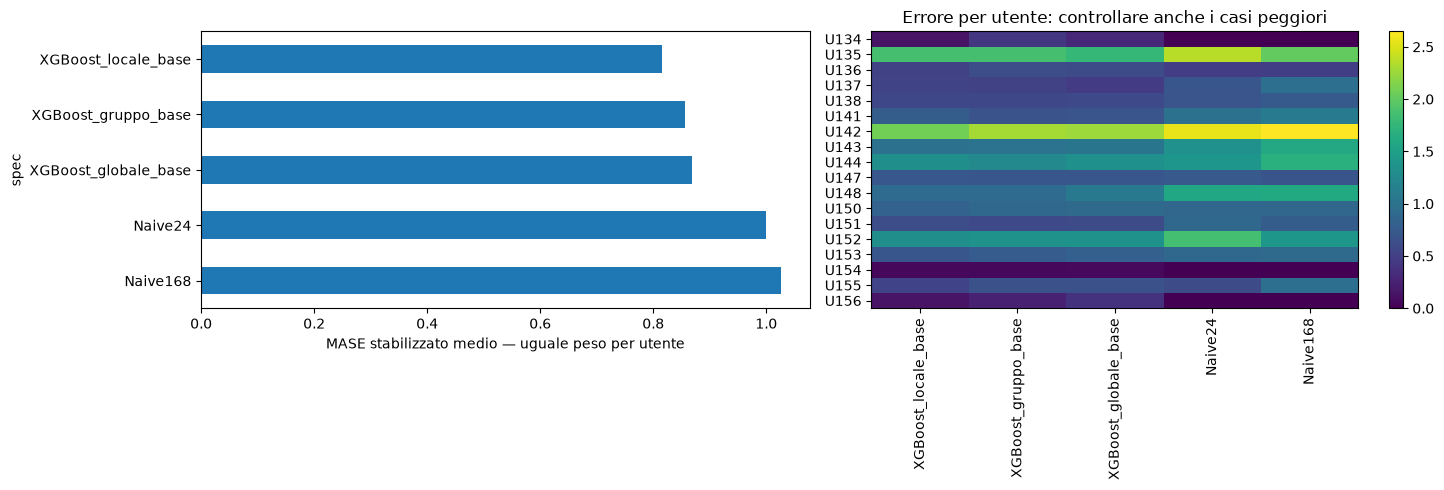

In [5]:
baseline_user = per_user.xs('Naive168').MAE
win_users = per_user.MAE.unstack('spec').lt(baseline_user,axis=0).mean().rename('quota_utenti_con_MAE_medio_migliore')
display(win_users.to_frame())
display(development.groupby(['spec','origin','seed']).MASE_stabilizzato.mean().unstack('spec'))
display(development.groupby('spec')[['MAE_low','MAE_transition','low_hours','transition_hours']].mean())

fig, axes = plt.subplots(1,2,figsize=(15,5))
ranking.score.plot.barh(ax=axes[0]);axes[0].invert_yaxis()
axes[0].set_xlabel('MASE stabilizzato medio — uguale peso per utente')
matrix = per_user.MASE_stabilizzato.unstack('spec').reindex(columns=ranking.index)
im = axes[1].imshow(matrix.to_numpy(),aspect='auto',cmap='viridis')
axes[1].set_yticks(range(len(matrix)),matrix.index)
axes[1].set_xticks(range(len(matrix.columns)),matrix.columns,rotation=90)
axes[1].set_title('Errore per utente: controllare anche i casi peggiori')
fig.colorbar(im,ax=axes[1]);fig.tight_layout();plt.show()
fig.savefig(OUT/'confronto_sviluppo.png',dpi=160,bbox_inches='tight')


## 6. Congelare la scelta e valutare il periodo finale
Si sceglie un **sistema** (algoritmo + strategia + uso del meteo) sulla classifica di sviluppo.
Può vincere anche una baseline. Sul finale si mantengono quel sistema e la sua griglia: il tuning interno
può essere ripetuto sul passato a ogni origine, come previsto dal protocollo. Nessun risultato finale
cambia questa scelta. Durante una valutazione rolling, le osservazioni già arrivate possono entrare nel
training delle origini successive, ma non nelle decisioni sulla famiglia di modelli.

`RUN_FINAL=False` lascia il periodo riservato. Per eseguirlo cambiare il flag qui sotto **dopo** aver
esaminato e fissato lo sviluppo. Non serve ripetere la cella di configurazione o lo sviluppo.
Il file di scelta viene scritto prima del calcolo e non può essere sostituito da una scelta diversa.
Il notebook rifiuta di sovrascrivere una valutazione finale già completata nella stessa cartella.


In [7]:
chosen = ranking.index[0]
locked = dict(chosen=chosen,protocol_sha256=hashlib.sha256(json.dumps(PROTOCOL,sort_keys=True).encode()).hexdigest())
lock_file = OUT/'scelta_congelata.json'
if lock_file.exists():
    assert json.loads(lock_file.read_text())==locked, 'Scelta già congelata diversa: non riutilizzare questo finale.'
else:
    lock_file.write_text(json.dumps(locked,indent=2))
print('Sistema scelto sullo sviluppo:', chosen)

classifica_utenti = (per_user.xs(chosen, level="spec").sort_values("MASE_stabilizzato"))
display(classifica_utenti)

# Impostare qui True e rieseguire solo questa cella quando si è pronti per la valutazione finale.
ESEGUI_FINALE = RUN_FINAL
if ESEGUI_FINALE:
    final_dir = OUT/'finale'
    if (final_dir/'metriche.csv').exists():
        raise RuntimeError('Finale già completato: leggere i risultati esistenti, senza sovrascriverli.')
    chosen_specs = [spec for spec in SPECS if spec['name']==chosen]
    final_metrics, final_predictions, final_search = bench.run_benchmark(
        panel,city,weather,USERS,FINAL_ORIGINS,chosen_specs,CFG,final_dir)
    final_rank, final_users = bench.leaderboard(final_metrics)
    display(final_rank)
    display(final_users)
    print('La scelta rimane:',chosen,'anche se una baseline è migliore sul finale.')
else:
    print('Periodo finale non eseguito. Scelta salvata in:',lock_file)


Sistema scelto sullo sviluppo: XGBoost_locale_base


,MASE_stabilizzato,RMSE,MAE,skill_naive168,beats_naive168
user,,,,,
U154,0.057047,1.383064,1.202845,NaN,0.0
U134,0.134816,0.074928,0.068061,NaN,0.0
U156,0.143901,8.620234,8.576193,NaN,0.0
U136,0.519587,46.542375,34.330369,0.256895,0.5
U155,0.535575,165.218125,126.934852,0.421669,1.0
U137,0.541626,7.097807,4.629846,0.376423,1.0
U138,0.571811,112.294986,89.890244,0.235972,1.0
U151,0.624912,483.589709,368.233141,0.201027,1.0
U153,0.705935,902.363384,741.159959,0.221327,1.0


Periodo finale non eseguito. Scelta salvata in: /Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/datasets/risultati_multiutente/pilota_20261003_102429_512308/scelta_congelata.json


## 7. Estensioni e interpretazione
Il profilo esteso confronta base e meteo storico (temperatura, punto di rugiada, umidità, vento,
raffiche, pressione della città associata). Il futuro contiene solo calendario; il meteo è ritardato
un’ora, imputato causalmente con ffill limitato e statistiche del fit. TFT usa le variabili meteo
solo nell’encoder. Gli eventi estremi annotati non sono inclusi in questo benchmark: aggiungerli
sarebbe una terza variante da dichiarare prima della selezione.

Le reti lavorano su CPU e fino a 100 epoche, con early stopping sul MASE stabilizzato interno.
La loss di training è MSE sui consumi normalizzati; non coincide con il criterio di selezione.
La griglia rimane contenuta: "migliore" significa migliore tra le alternative e i periodi provati.

Prima di una pubblicazione:
- aumentare origini di valutazione e ampiezza della ricerca con budget dichiarato;
- riportare incertezza dei miglioramenti rispettando dipendenza temporale e tra utenti;
- separare l’esperimento su impianti già noti da un test con interi utenti mai visti;
- verificare l’effetto della stabilizzazione del MASE e del pannello a copertura completa;
- conservare anche risultati negativi e fallimenti.

Gli output contengono protocollo, copertura, metriche, previsioni per orizzonte, gruppi, ricerche,
curve dei candidati e scelta congelata. I pesi dei modelli non sono salvati: questo è un benchmark,
non ancora un pacchetto di inferenza da mettere in produzione.
